### What is a Policy
A policy represents a map from state/observation space $\mathcal{S}/\mathcal{O}$ to action space $\mathcal{A}$.
There are two branch of policies: stochastic and deterministic. In RL, we usually use stochastic policy and denote as:
$$
\pi_{\theta}(a|s)
$$
where the subscript $\theta$ represents the policy's parameters. A stochastic policy outputs a distribution on action space given the current state $s$

In [39]:
import torch
from torch.nn import Module # Neural Network Module
from torch import nn
import numpy as np
from torch import distributions
from typing import Union

print (torch.__version__)

device = None
use_gpu = True
gpu_id=0
if torch.cuda.is_available() and use_gpu:
    device = torch.device("cuda:" + str(gpu_id))
    print("Using GPU id {}".format(gpu_id))
else:
    device = torch.device("cpu")
    print("Using CPU.")

# support function to build Neural Network

def build_mlp(
        input_size: int,
        output_size: int,
        n_layers: int,
        size: int,
):
    layers = []
    in_size = input_size
    for _ in range(n_layers):
        layers.append(nn.Linear(in_size, size))
        layers.append(nn.Tanh()) # choose Tanh as activation
        in_size = size
    layers.append(nn.Linear(in_size, output_size))
    layers.append(nn.Identity()) # Output layer is identity

    mlp = nn.Sequential(*layers)
    mlp.to(device)
    return mlp

2.9.1+cu126
Using GPU id 0


We make a Policy Network using the pytorch_util file that contains some supporting functions

In [26]:
# Environment
import gymnasium as gym
env = gym.make('CartPole-v1')

action_dim = env.action_space.n # 2
obs_dim = env.observation_space.shape[0] # 4

input_size = obs_dim
output_size = action_dim 
n_layers = 2 # number of hidden layers
size = 32 # number of units per layer

policy = build_mlp(input_size=obs_dim, output_size= action_dim,
                       n_layers= n_layers, size=size)

policy




Sequential(
  (0): Linear(in_features=4, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=2, bias=True)
  (5): Identity()
)

### Sample action from a Policy
A policy maps a state to action by outputing a distribution over the action space given state s
For a discrete system like cartpole in gymnasium, the policy outputa Categorical Distribution.

### Converting Raw Logits to a Categorical Distribution

A policy network outputs a vector of raw, unconstrained real-valued scores called **logits**:
$$z = [z_1, z_2, \dots, z_K]$$

To convert these logits into a valid probability distribution over $K$ discrete actions, we apply the **Softmax** function:

$$p_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$$

- **Non-negativity:** The exponential $e^{z_i} > 0$ ensures every probability is strictly positive.
- **Normalization:** Dividing by the sum $\sum_{j=1}^{K} e^{z_j}$ guarantees all probabilities sum to 1:
$$\sum_{i=1}^{K} p_i = 1$$

The resulting vector $p = [p_1, p_2, \dots, p_K]$ defines the parameter of the **Categorical distribution** $\pi_\theta(a \mid s)$, where:
$$\pi_\theta(a = i \mid s) = p_i$$

In [46]:
def get_action(policy: nn.Sequential, observation: np.ndarray):
    # input: policy: the policy we want to sample an action
    # input: observation (dim_obs)
    # output: a sample action in action space (dim_action)
    obs_tensor = torch.as_tensor(observation, dtype=torch.float32, device=device)

    # feed to the policy network but dont compute the gradient to save the computation
    with torch.no_grad():
        logits = policy(obs_tensor) # forward to the policy network, get raw score

        # convert to distribution
        action_distribution = distributions.Categorical(logits=logits)

        # sample an action from the distribution
        action = action_distribution.sample()
        
    return action.item()

obs,_ = env.reset()
action = get_action(policy=policy, observation = obs)


### Improving Policy with policy gradient


In [108]:
from typing import Dict
from torch import optim

gamma = 0.99 # discounted factor in caculating return

learning_rate = 0.005
policy = build_mlp(input_size=obs_dim, output_size=action_dim, n_layers=n_layers, size=size)
policy.optimizer = optim.Adam(policy.parameters(), lr=learning_rate)


def sample_rollout (env: gym.Env, policy: nn.Sequential) -> Dict[str, np.ndarray]:
    ob,_ = env.reset()
    obs, acts, rewards, next_obs = [], [], [], []
    done = False

    while not done:
        sample_action = get_action(policy=policy, observation = ob)

        next_ob, rw, terminated, trunc, _ = env.step(sample_action)

        obs.append(ob)
        acts.append(sample_action)
        rewards.append(rw)
        next_obs.append(next_ob)

        ob = next_ob

        done = terminated or trunc
    return {
        "observation": np.array(obs, dtype=np.float32),
        "reward": np.array(rewards, dtype=np.float32),
        "action": np.array(acts, dtype=np.float32),
        "next_observation": np.array(next_obs, dtype=np.float32),
    }

def compute_trajectory_rtg (trajectory: Dict[str, np.ndarray]) -> np.ndarray:
   
    reward = trajectory["reward"]
    rtg = np.zeros_like(reward)
    reward_len = len(reward)
    for j in reversed(range(reward_len)):
        rtg[j] = reward[j] + (rtg[j+1]*gamma if j+1 < reward_len else 0)
    return rtg

# Training loop
num_iters = 50 # number of iteration
num_of_rollout_per_iter = 100

batch_traj = []
batch_rtg = []
total_batch_loss = 0.0

learning_rate = 0.001
policy.optimizer = optim.Adam(policy.parameters(), lr = learning_rate)

for i in range(num_iters):
    batch_traj = []
    batch_rtg = []
    total_batch_loss = 0.0

    # sample trajectories
    for j in range(num_of_rollout_per_iter):
        sample_traj = sample_rollout(env= env, policy=policy)
        batch_traj.append(sample_traj)

    # compute batch rtg
    for traj in batch_traj:
        rtg_trj = compute_trajectory_rtg(traj)
        batch_rtg.append(rtg_trj)

        # compute loss for each trajectory
        obs_tensor = torch.as_tensor(traj["observation"], dtype=torch.float32, device=device)
        acts_tensor = torch.as_tensor(traj["action"], dtype=torch.float32, device=device)
        rtg_trj_tensor = torch.as_tensor(rtg_trj, dtype=torch.float32, device=device)

        logits = policy(obs_tensor) # forward to the policy network, get raw score
        # convert to distribution
        action_distribution = distributions.Categorical(logits=logits)
        log_dist = action_distribution.log_prob(acts_tensor)
        loss_traj = -(log_dist * rtg_trj_tensor)
        total_batch_loss+=torch.sum(loss_traj)

    # compute total loss
    loss = total_batch_loss / num_of_rollout_per_iter

    # # optimization
    policy.optimizer.zero_grad()
    loss.backward()
    policy.optimizer.step()

    if i%5 == 0:
        print(f"Iter {i}  Average episode reward: {np.mean([t['reward'].sum() for t in batch_traj]):.1f}")


    # print (loss)    
    


Iter 0  Average episode reward: 21.8
Iter 5  Average episode reward: 24.0
Iter 10  Average episode reward: 27.4
Iter 15  Average episode reward: 28.7
Iter 20  Average episode reward: 41.0
Iter 25  Average episode reward: 39.5
Iter 30  Average episode reward: 43.5
Iter 35  Average episode reward: 53.2
Iter 40  Average episode reward: 56.0
Iter 45  Average episode reward: 62.9


In [112]:
from typing import Dict
from torch import optim

gamma = 0.99 # discounted factor in caculating return

def sample_rollout (env: gym.Env, policy: nn.Sequential) -> Dict[str, np.ndarray]:
    ob,_ = env.reset()
    obs, acts, rewards, next_obs = [], [], [], []
    done = False

    while not done:
        sample_action = get_action(policy=policy, observation = ob)

        next_ob, rw, terminated, trunc, _ = env.step(sample_action)

        obs.append(ob)
        acts.append(sample_action)
        rewards.append(rw)
        next_obs.append(next_ob)

        ob = next_ob

        done = terminated or trunc
    return {
        "observation": np.array(obs, dtype=np.float32),
        "reward": np.array(rewards, dtype=np.float32),
        "action": np.array(acts, dtype=np.float32),
        "next_observation": np.array(next_obs, dtype=np.float32),
    }

def compute_trajectory_rtg (trajectory: Dict[str, np.ndarray]) -> np.ndarray:
   
    reward = trajectory["reward"]
    rtg = np.zeros_like(reward)
    reward_len = len(reward)
    for j in reversed(range(reward_len)):
        rtg[j] = reward[j] + (rtg[j+1]*gamma if j+1 < reward_len else 0)
    return rtg

def update(
        policy: nn.Sequential,
        obs: np.ndarray,
        actions: np.ndarray,
        advantages: np.ndarray,
    ) -> dict:
    """Implements the policy gradient actor update."""
    obs = torch.as_tensor(obs, dtype=torch.float32, device=device)
    actions = torch.as_tensor(actions, dtype=torch.float32, device=device)
    advantages = torch.as_tensor(advantages, dtype=torch.float32, device=device)

    # one forward pass over all timesteps of all trajectories
    logits = policy(obs)
    dist = distributions.Categorical(logits=logits)
    log_probs = dist.log_prob(actions.long())
    loss = -(log_probs * advantages).mean()

    # optimizer step
    policy.optimizer.zero_grad()
    loss.backward()
    policy.optimizer.step()

    return {
        "Actor Loss": loss.item(),
    }

# Training loop
num_iters = 50 # number of iteration
num_of_rollout_per_iter = 10

learning_rate = 0.005
policy = build_mlp(input_size=obs_dim, output_size=action_dim, n_layers=n_layers, size=size)
policy.optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# logging
total_steps = 0
step_history = []
reward_history = []

for i in range(num_iters):

    # sample trajectories
    batch_traj = [sample_rollout(env=env, policy=policy) for _ in range(num_of_rollout_per_iter)]

    # flatten the batch: stack all timesteps of all trajectories into single arrays
    obs = np.concatenate([traj["observation"] for traj in batch_traj])
    actions = np.concatenate([traj["action"] for traj in batch_traj])
    rtg = np.concatenate([compute_trajectory_rtg(traj) for traj in batch_traj])

    # normalize reward-to-go over the whole batch -> advantages
    advantages = (rtg - rtg.mean()) / (rtg.std() + 1e-8)

    info = update(policy, obs, actions, advantages)

    # record env steps and average return of this iteration
    total_steps += len(obs)
    avg_return = np.mean([traj["reward"].sum() for traj in batch_traj])
    step_history.append(total_steps)
    reward_history.append(avg_return)

    if i%5 == 0:
        print(f"Iter {i}  Steps {total_steps}  Average episode reward: {avg_return:.1f}  Loss: {info['Actor Loss']:.4f}")

Iter 0  Steps 165  Average episode reward: 16.5  Loss: 0.0070
Iter 5  Steps 1650  Average episode reward: 29.5  Loss: -0.0173
Iter 10  Steps 4066  Average episode reward: 53.5  Loss: -0.0205
Iter 15  Steps 7556  Average episode reward: 90.1  Loss: -0.0059
Iter 20  Steps 12725  Average episode reward: 132.3  Loss: -0.0181
Iter 25  Steps 20878  Average episode reward: 182.8  Loss: -0.0028
Iter 30  Steps 32730  Average episode reward: 294.0  Loss: -0.0217
Iter 35  Steps 51055  Average episode reward: 497.8  Loss: -0.0114
Iter 40  Steps 74385  Average episode reward: 455.5  Loss: -0.0150
Iter 45  Steps 97557  Average episode reward: 467.2  Loss: -0.0139


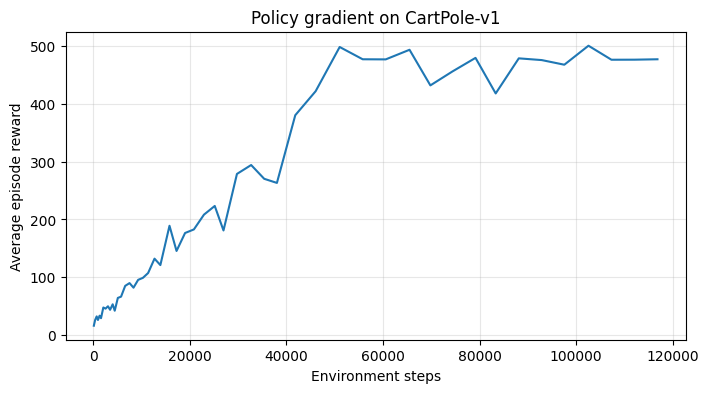

In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(step_history, reward_history)
plt.xlabel("Environment steps")
plt.ylabel("Average episode reward")
plt.title("Policy gradient on CartPole-v1")
plt.grid(alpha=0.3)
plt.show()